# <center> Практические задания по цифровой обработке сигналов </center>
# <center> Четвертая лабораторная работа </center>
# <center> Акустические признаки </center>

In [1]:
import librosa
import numpy as np
import scipy 
import scipy.fft
import IPython.display as ipd
import matplotlib.pyplot as plt
import librosa.display
import librosa.filters
import hashlib
from glob import glob
import os
import sklearn

%matplotlib inline
%config InlineBackend.figure_format = 'retina'
# ['retina', 'png', 'jpeg', 'svg', 'pdf']

In [2]:
# Функция отрисовки аудио сигнала. 
def draw_waveform(wav, sr, figsize=(8, 4)):
    # Отрисовка звукового сигнала во временной области
    plt.figure(figsize=figsize)
    librosa.display.waveplot(wav, sr=sr)
    plt.show()

In [3]:
# Для выполнения задания нам понадобится датасет yes/no. 
# Про датасет можно почитать тут https://www.openslr.org/1/

# Скачаем его
![ ! -f  waves_yesno.tar.gz ] && wget https://www.openslr.org/resources/1/waves_yesno.tar.gz
# И распакуем
!tar -xvzf waves_yesno.tar.gz

# P.S если у вас Windows, или по каким-либо еще причинам данные не скачались, 
# то их можно скачать руками отсюда: https://www.openslr.org/1/

x waves_yesno/
x waves_yesno/1_0_0_0_0_0_1_1.wav
x waves_yesno/1_1_0_0_1_0_1_0.wav
x waves_yesno/1_0_1_1_1_1_0_1.wav
x waves_yesno/1_1_1_1_0_1_0_0.wav
x waves_yesno/0_0_1_1_1_0_0_0.wav
x waves_yesno/0_1_1_1_1_1_1_1.wav
x waves_yesno/0_1_0_1_1_1_0_0.wav
x waves_yesno/1_0_1_1_1_0_1_0.wav
x waves_yesno/1_0_0_1_0_1_1_1.wav
x waves_yesno/0_0_1_0_1_0_0_0.wav
x waves_yesno/0_1_0_1_1_0_1_0.wav
x waves_yesno/0_0_1_1_0_1_1_0.wav
x waves_yesno/1_0_0_0_1_0_0_1.wav
x waves_yesno/1_1_0_1_1_1_1_0.wav
x waves_yesno/0_0_1_1_1_1_0_0.wav
x waves_yesno/1_1_0_0_1_1_1_0.wav
x waves_yesno/0_0_1_1_0_1_1_1.wav
x waves_yesno/1_1_0_1_0_1_1_0.wav
x waves_yesno/0_1_0_0_0_1_1_0.wav
x waves_yesno/0_0_0_1_0_0_0_1.wav
x waves_yesno/0_0_1_0_1_0_1_1.wav
x waves_yesno/0_0_1_0_0_0_1_0.wav
x waves_yesno/1_1_0_1_1_0_0_1.wav
x waves_yesno/0_1_1_1_0_1_0_1.wav
x waves_yesno/0_1_1_1_0_0_0_0.wav
x waves_yesno/README~
x waves_yesno/0_1_0_0_0_1_0_0.wav
x waves_yesno/1_0_0_0_0_0_0_1.wav
x waves_yesno/1_1_0_1_1_0_1_1.wav
x waves_yes

sampling rate: 22050 Hz


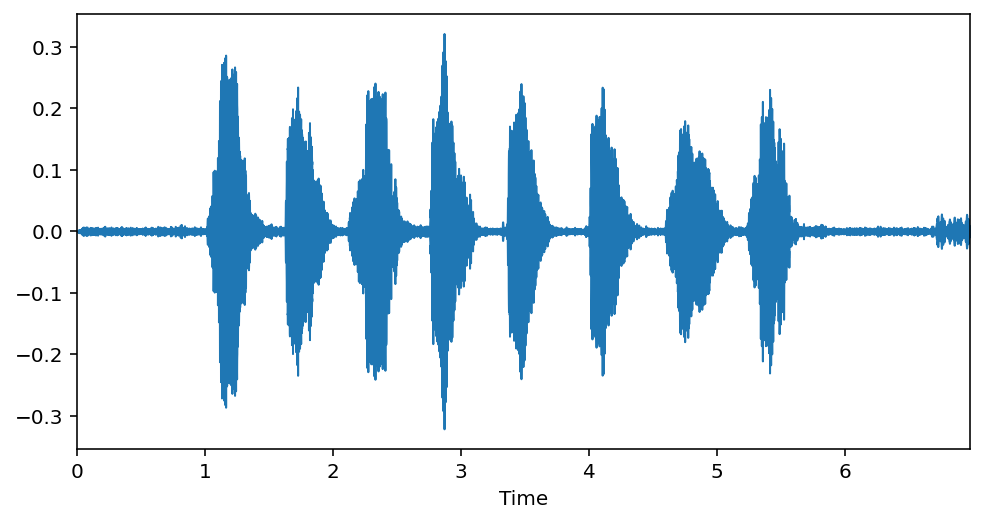

In [4]:
# Загрузим один из файлов
wav, sr = librosa.load("waves_yesno/0_1_0_1_1_1_0_0.wav") 
#automatically resampled to the default sr = 22050 Hz
print(f'sampling rate: {sr} Hz')
draw_waveform(wav, sr)
ipd.Audio(wav, rate=sr)

Как можно услышать, в этом датасете произносятся какие-то два слова (yes/no на иврите). Каждый файл состоит из 8 произнесений. Метки слов указаны в названиях файлов.

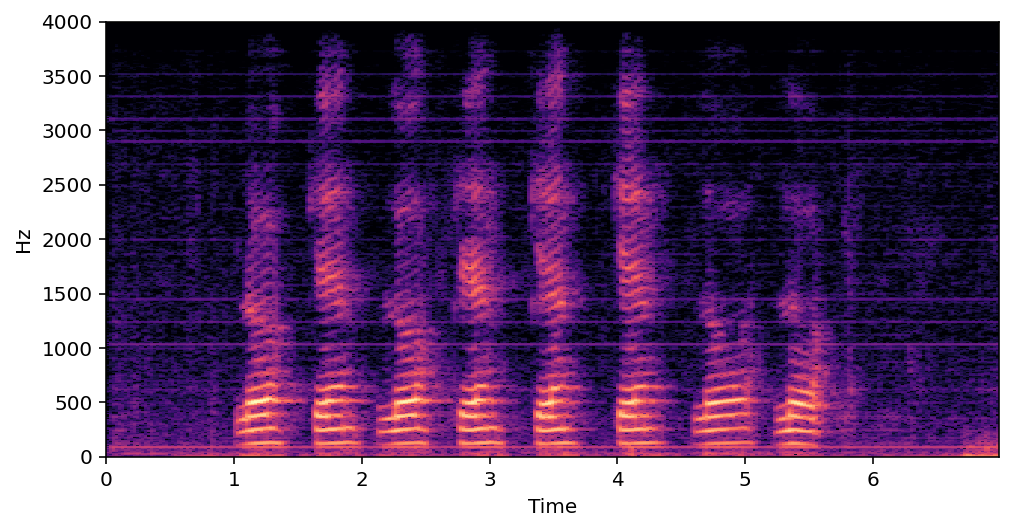

In [5]:
# Построим спектрограмму загруженного файла
stft = librosa.stft(wav)
stft_db = librosa.amplitude_to_db(abs(stft))
plt.figure(figsize=(8, 4))
librosa.display.specshow(stft_db, sr=sr, x_axis='time', y_axis='hz')
plt.ylim(0, 4000);

Последовательность слов в файле: 

**"ло", "кен", "ло", "кен", "кен", "кен", "ло", "ло"**

- "кен" = "да"
- "ло" = "нет"

# Задание 0.1: Анализ спектрограммы (0.5 балла)
1. Посмотрите на спектрограмму и попробуйте найти признаки, по которым можно отличить произнесение "yes" от "no". 
1. В каких частотах находится основная энергия этого речевого сигнала? 

1. Амплитудный спектр слова "кен" ("да") имеет больше высокоэнергетических составляющих в области частот более 1кГц, чем амплитудный спектр для слова "ло" ("нет").
2. Основная энергия речевого сигнала сосредоточена в частотах до 1 кГц.

# Задание 1: Мел-шкала (1 балл)
Нарисовать спектрограму в [mel-шкале](https://en.wikipedia.org/wiki/Mel_scale). 
Использовать формулу, представленную Дугласом О'Шонесси.

In [6]:
def mel(f):
    return 2595.0 * np.log10(1.0 + f / 700.0)  # convert Hz to Mel

In [7]:
def test_mel():
    x = np.random.randint(100, size=(1000, 100))
    x_mel = mel(x)
    x_hz = 700.0 * (10.0 ** (x_mel / 2595.0) - 1.0)
    assert np.allclose(x, x_hz), "TEST Hertz -> Mel -> Hertz  failed. "
    print("All ok!")
test_mel()

All ok!


# Мел-фильтры
Одними из наиболее популярных акустических признаков являются Filter Banks (fbanks). 
fbanks вычисляются применением нескольких (количество фильтров = количество fbanks) треугольных фильтров к мел-спектрограмме. Чтобы не делать два действия со спектрограммой, переход к мел-шкале и применение фильтров в мел-шкале можно заменить на перевод мел-фильтров в Герц-шкалу и применение их к Герц-спектрограмме.



# Задание 2 (3 балла)
Реализуйте функцию вычисления fbank. 

In [8]:
def mel_filters(sr, n_fft, n_mels):
    
    fmin, fmax = 0.0, sr / 2.0
    fbank = np.zeros((n_mels, n_fft // 2 + 1))
    
    # center freqs of each FFT bin
    fft_freqs = np.linspace(fmin, fmax, n_fft // 2 + 1, endpoint=True)
    # centers of mel bands (uniformly spaced between limits)
    mels = np.linspace(fmin, 2595.0 * np.log10(1.0 + fmax / 700.0), n_mels + 2)
    mel_freqs = 700.0 * (10.0 ** (mels / 2595.0) - 1.0) # convert Mel to Hz
    
    fdiff = np.diff(mel_freqs)
    slopes = np.empty((n_mels + 2, n_fft // 2 + 1))
    for i in range(n_mels + 2):
        for j in range(n_fft // 2 + 1):
            slopes[i, j] = mel_freqs[i] - fft_freqs[j]
    # apply the 'subtract' op to all pairs (mel_freqs, fft_freqs) 
    # slopes = np.subtract.outer(mel_freqs, fft_freqs)

    for i in range(n_mels):
        # lower and upper slopes for all bins
        lower, upper = -slopes[i] / fdiff[i], slopes[i + 2] / fdiff[i + 1]
        # intersect lower and upper slopes with each other and zero
        fbank[i] = np.maximum(0, np.minimum(lower, upper))
    
    # mel is scaled to be approx constant energy per channel
    enorm = 2.0 / (mel_freqs[2:n_mels + 2] - mel_freqs[:n_mels])

    return fbank * enorm.reshape(-1, 1)

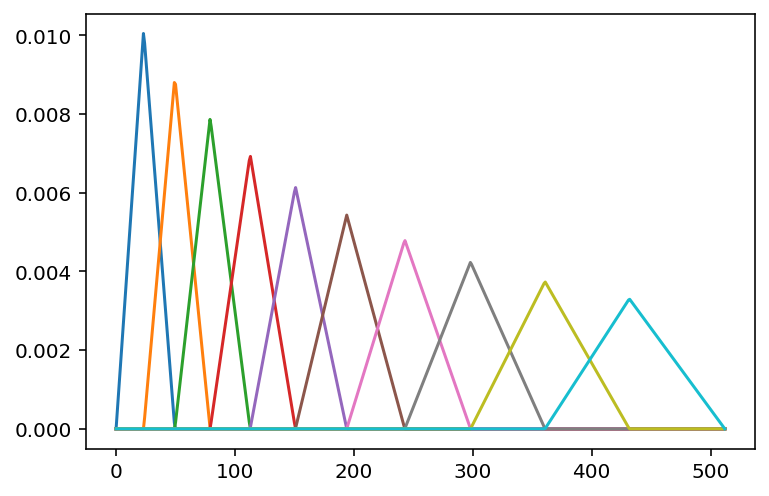

In [9]:
# test fbank plot
plt.plot(mel_filters(4096, 1024, 10).T);

In [10]:
assert mel_filters(32, 46, 4).shape == (4, 24) and \
       mel_filters(65, 45, 5).shape == (5, 23), "Wrong shape"
assert np.allclose(mel_filters(16, 8, 4), librosa.filters.mel(16, 8, n_mels=4, htk=True))
assert np.allclose(mel_filters(8600, 512, 40), librosa.filters.mel(8600, 512, n_mels=40, htk=True))
print("All ok!")

All ok!


In [11]:
def stft(x, n_fft=2048, hop_length=512, window='hann'): # from Lab2
    #  Short-time Fourier transform
    # x - signal
    # n_fft - fft window size 
    # hop_length - step size between ffts
    # window - window type. See scipy.signal.get_window
    # return spectrogram
    
    fft_window = scipy.signal.get_window(window, n_fft, fftbins=True)
    fft_window = fft_window.reshape((-1, 1))
    # padding
    x = np.pad(x, int(n_fft // 2), mode='reflect')
    # number of frames
    n_frames = 1 + int((len(x) - n_fft) / hop_length)
    # vertical stride: one sample, horizontal stride: hop_length samples
    y_frames = np.lib.stride_tricks.as_strided(x, shape=(n_fft, n_frames), 
                                               strides=(x.itemsize, hop_length * x.itemsize))
    # spectrogram matrix
    stft_mat = np.empty((int(1 + n_fft // 2), y_frames.shape[1]), dtype=np.complex)
    str_c, col_c = stft_mat.shape[0], stft_mat.shape[1]

    for bl_beg in range(0, col_c, str_c):
        bl_end = min(bl_beg + str_c, col_c)
        stft_mat[:, bl_beg:bl_end] = scipy.fft.fft(y_frames[:, bl_beg:bl_end] * fft_window, 
                                                   axis=0)[:str_c]

    return stft_mat

def get_fbanks(wav: np.ndarray, sr: int, window_ms=25, step_ms=10, n_fbanks=40):
    # wav - input signal
    # sr - sample rate
    # window_ms - window length in milliseconds
    # step_ms - stft step in milliseconds
    # n_fbanks - number of filters
    # return fbank matrix [n_fbanks, time]
    
    n_fft = window_ms * sr // 1000
    hop_length = step_ms * sr // 1000
    specgram = np.abs(stft(wav, n_fft=n_fft, hop_length=hop_length)) ** 2 # power spectrum
    mel_basis = mel_filters(sr, n_fft, n_mels=n_fbanks)

    return np.dot(mel_basis, specgram)

In [12]:
def test_fbank(wav, sr, window_ms=25, step_ms=10, n_fbanks=40):
    n_fft = window_ms * sr // 1000
    hop_length = step_ms * sr // 1000
    fbanks_lib = librosa.feature.melspectrogram(wav, sr, n_fft=n_fft, hop_length=hop_length, 
                                                n_mels=n_fbanks, htk=True)
    fbanks = get_fbanks(wav, sr, window_ms=window_ms, step_ms=step_ms, n_fbanks=n_fbanks)
    
    if fbanks_lib.shape != fbanks.shape:
        print("TEST FAILED")
        print(f"Shape {fbanks_lib.shape} != {fbanks.shape}")
    if not np.allclose(fbanks_lib, fbanks):
        print("TEST FAILED")
        print(f"Average diff is {np.mean(np.abs(fbanks_lib - fbanks))}")
        return -1
    print("TEST PASSED")
    return 0
assert test_fbank(wav[:sr*1], sr) == 0, "1 sec wav test failed"
assert test_fbank(wav, sr) == 0 , "All wav test failed"
print("All ok!")

TEST PASSED
TEST PASSED
All ok!


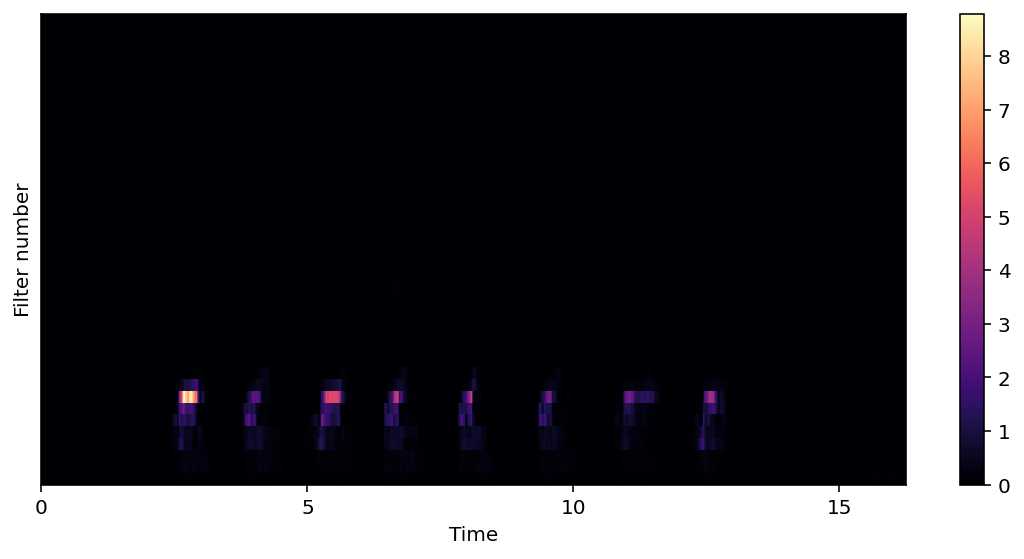

In [13]:
fbanks = get_fbanks(wav, sr)

plt.figure(figsize=(8, 4))
librosa.display.specshow(fbanks, sr=sr, x_axis='time')
plt.ylabel("Filter number")
plt.colorbar()
plt.tight_layout()
plt.show()

# Задание 3 (3 балла)
Реализовать вычисление [mfcc](https://en.wikipedia.org/wiki/Mel-frequency_cepstrum)



In [14]:
from scipy.fftpack import dct

def get_mfcc(wav: np.ndarray, sr: int, window_ms=25, step_ms=10, n_mfcc=13):
    # wav - input signal
    # sr - sample rate
    # window_ms - window length in milliseconds
    # step_ms - stft step in milliseconds
    # n_mfcc - number of filters
    # return mfcc matrix [n_mfcc, time]
    
    fbanks = get_fbanks(wav, sr, window_ms=window_ms, step_ms=step_ms) # default n_fbanks=40
    log_fbanks = 10.0 * np.log10(np.maximum(1e-10, fbanks)) # min thresh
    log_fbanks -= 10.0 * np.log10(np.maximum(1e-10, 1.0)) 
    log_fbanks = np.maximum(log_fbanks, log_fbanks.max() - 80.0) # max 80 dB
    
    return dct(log_fbanks, axis=0, type=2, norm='ortho')[:n_mfcc]

In [15]:
def test_mfcc(wav, sr, window_ms=25, step_ms=10, n_mfcc=13):
    n_fft = window_ms * sr // 1000
    hop_length = step_ms * sr // 1000
    mfcc_lib = librosa.feature.mfcc(wav, sr, n_fft=n_fft, hop_length=hop_length, 
                                    n_mfcc=n_mfcc, n_mels=40, htk=True)
    mfcc = get_mfcc(wav, sr, window_ms=window_ms, step_ms=step_ms, n_mfcc=n_mfcc)
    
    if mfcc_lib.shape != mfcc.shape:
        print("TEST FAILED")
        print(f"Shape {mfcc_lib.shape} != {mfcc.shape}")
    if not np.allclose(mfcc_lib, mfcc, atol=2e-5): # default atol=1e-8
        print("TEST FAILED")
        print(f"Average diff is {np.mean(np.abs(mfcc_lib - mfcc))}")
        return -1
    print("TEST PASSED")
    return 0
assert test_mfcc(wav[:sr*1], sr) == 0, "1 sec wav test failed"
assert test_mfcc(wav, sr) == 0 , "All wav test failed"
print("All ok!")

TEST PASSED
TEST PASSED
All ok!


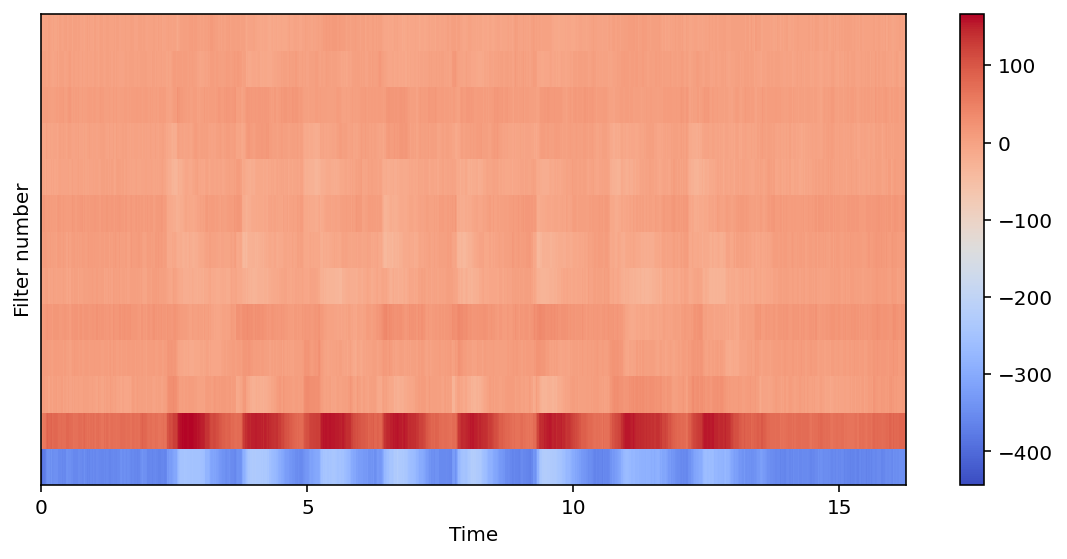

In [16]:
mfcc = get_mfcc(wav, sr)
plt.figure(figsize=(8, 4))
librosa.display.specshow(mfcc, sr=sr, x_axis='time')
# sklearn.preprocessing.scale(mfcc, axis=1)
plt.ylabel("Filter number")
plt.colorbar()
plt.tight_layout()
plt.show()

# Классификация слов
Построим простую систему, классифицирующую слова yes/no.

Загрузим весь датасет

In [17]:
def load_yn_dataset(directory):
    X, labels = [], []
    for f in glob(directory +"/*.wav"):
        name = os.path.basename(f)[:-4]
        y = [int(l) for l in name.split("_")]
        x, _ = librosa.load(f)
        X.append(x)
        labels.append(y)
        
    return X, labels
        
X, Y = load_yn_dataset("waves_yesno/")

Файлы в наборе данных различной длительности от 5 до 7 секунд.

min duration: 4.94 s
max duration: 6.98 s


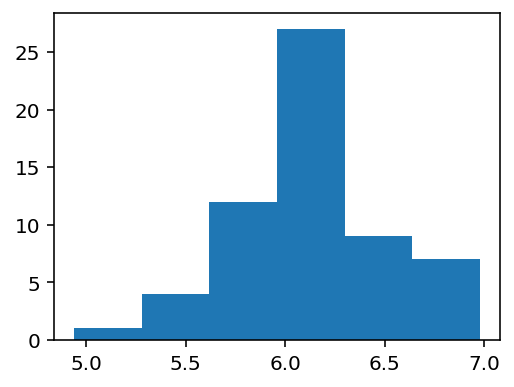

In [18]:
lengths_wav = []
for x in X:
    lengths_wav.append(x.shape[0] / sr)
print(f'min duration: {min(lengths_wav)} s') 
print(f'max duration: {max(lengths_wav)} s')
plt.figure(figsize=(4, 3))
plt.hist(lengths_wav, bins=6);

# Задание *4 (1 балл)
Voice Activity Detector (VAD) определяет, есть ли речь в текущем кадре или нет.
Реализуйте простой VAD.
Настройте VAD, чтобы хорошо определялись границы слов.

Изучение набора данных показало, что в одном из примеров (`X[21]`) записано семь слов, при этом в соответствующей метке их восемь!

Y[21] label: [0, 1, 0, 1, 0, 0, 0, 0]


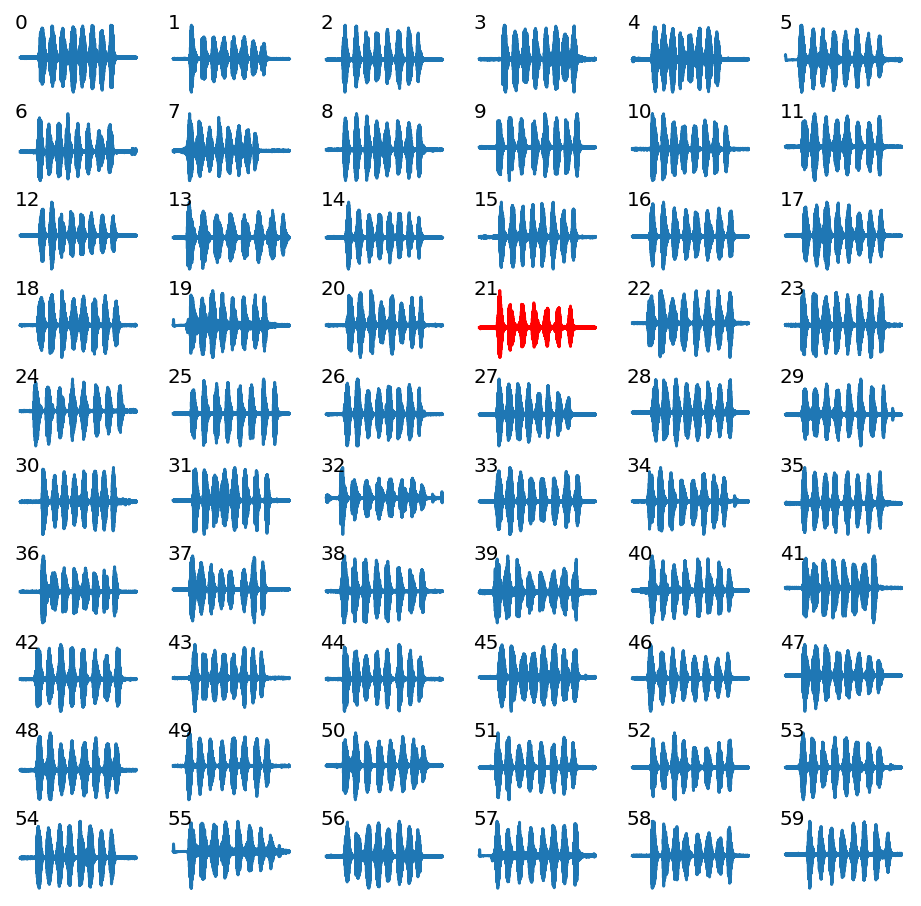

In [19]:
print(f'Y[21] label: {Y[21]}') # wrong label

_, axes = plt.subplots(10, 6, figsize=(8, 8))
for i, ax_i in enumerate(axes):
    for j, ax_j in enumerate(ax_i):
        ind = i * len(ax_i) + j
        if ind == 21: # wrong label
            ax_j.plot(X[ind], c='r')
        else:
            ax_j.plot(X[ind])
        ax_j.set_axis_off()
        ax_j.annotate(text=ind, xy=(0., 0.9), xycoords='axes fraction')
plt.show()

Согласно [описанию](https://www.openslr.org/1/), все слова в наборе данных произносятся одним человеком (тембр фиксирован). Большая часть энергии сигнала сосредоточена в диапазоне от 100 до 700 Гц. Именно в этом диапазоне мы и будем считать энергию в нашем VAD.

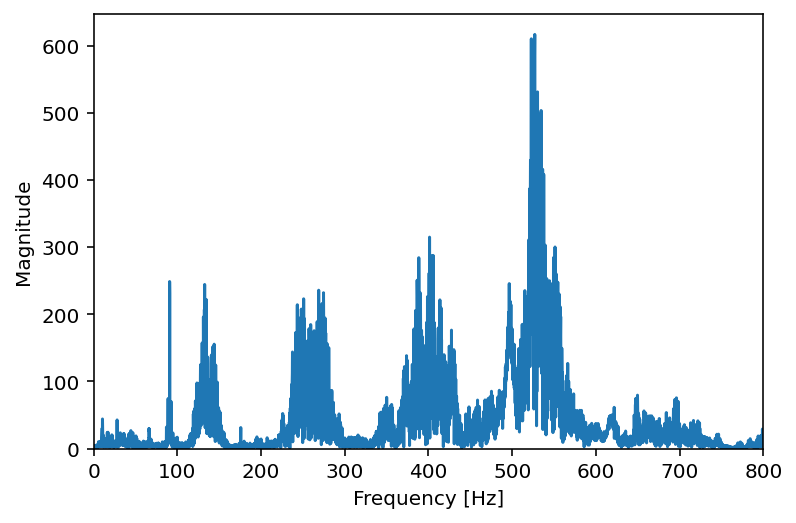

In [20]:
plt.plot(np.fft.fftshift(np.fft.fftfreq(X[0].shape[0], d=1/sr)),
         np.fft.fftshift(np.abs(np.fft.fft(X[0]))))
plt.ylabel('Magnitude')
plt.xlabel('Frequency [Hz]')
plt.gca().xaxis.set_ticks(np.arange(0, 801, 100))
plt.xlim(0, 800)
plt.ylim(0,);

Определим необходимые функции для VAD.

In [21]:
def enframe(x, win_len, hop_len):
    # receives a 1D numpy array and divides it into frames
    # outputs a numpy matrix with the frames on the rows
    x = np.squeeze(x)
    if x.ndim != 1:
        raise TypeError("enframe input must be a 1-dimensional array.")
    n_frames = 1 + np.int(np.floor((len(x) - win_len) / float(hop_len)))
    x_framed = np.zeros((n_frames, win_len))
    for i in range(n_frames):
        x_framed[i] = x[i * hop_len : i * hop_len + win_len]
    return x_framed

def deframe(x_framed, win_len, hop_len):
    # interpolates 1D data with framed alignments into persample values.
    # This function helps as a visual aid and can also be used to change 
    # frame-rate for features, e.g. energy, zero-crossing, etc.
    n_frames = len(x_framed)
    n_samples = n_frames * hop_len + win_len
    x_samples = np.zeros((n_samples, 1))
    for i in range(n_frames):
        x_samples[i * hop_len : i * hop_len + win_len] = x_framed[i]
    return x_samples

def zero_mean(xframes):
    # returns zero-mean frames
    m = np.mean(xframes,axis=1)
    xframes = xframes - np.tile(m,(xframes.shape[1], 1)).T
    return xframes

def compute_nrg(xframes):
    # calculate per frame energy
    n_frames = xframes.shape[1]
    spectrum = power_spectrum(xframes)
    freqs = np.fft.fftfreq(n_frames) * sr
    xxframes = np.where((abs(freqs) > 100) & (abs(freqs) < 700), spectrum, 0.0) #### frequencies ####
    result = np.diagonal(np.dot(xxframes, xxframes.T)) / float(n_frames)
    result = np.convolve(result, np.ones(3) / 3, mode='same') #### moving avg ####
    return result

def compute_log_nrg(xframes):
    # calculate per frame energy in log scale
    n_frames = xframes.shape[1]
    raw_nrgs = np.log(compute_nrg(xframes + 1e-5)) / float(n_frames)
    return (raw_nrgs - np.mean(raw_nrgs)) / np.sqrt(np.var(raw_nrgs))

def power_spectrum(xframes):
    # xframes: input signal, each row is one frame
    X = np.fft.fft(xframes, axis=1)
    X = np.abs(X) ** 2
    return np.sqrt(X)

def nrg_vad(xframes, percent_thr, nrg_thr=0., context=3): #### nrg_thr, context ####
    # Picks frames with high energy as determined 
    # by a user defined threshold.
    # This function also uses a 'context' parameter to
    # resolve the fluctuative nature of thresholding.
    # 'context' is an integer value determining the number
    # of neighboring frames that should be used to decide
    # if a frame is voiced.
    xframes = zero_mean(xframes)
    n_frames = xframes.shape[0]
    # Compute per frame energies
    xnrgs = compute_log_nrg(xframes)
    xvad = np.zeros((n_frames, 1))
    for i in range(n_frames):
        start = max(i - context, 0)
        end = min(i + context, n_frames - 1)
        n_above_thr = np.sum(xnrgs[start:end] > nrg_thr)
        n_total = end - start + 1
        xvad[i] = 1. * ((float(n_above_thr) / n_total) > percent_thr)
    return xvad

**Проверка работоспособности детектора речи и настройка гиперпараметров**

Ещё одна особенность набора данных состоит в том, что в примере `X[13]` последнее слово записано ближе всего к концу записи! Границы обрезки звуковых файлов нужно выбрать с тем расчётом, чтобы не потерять слова. 

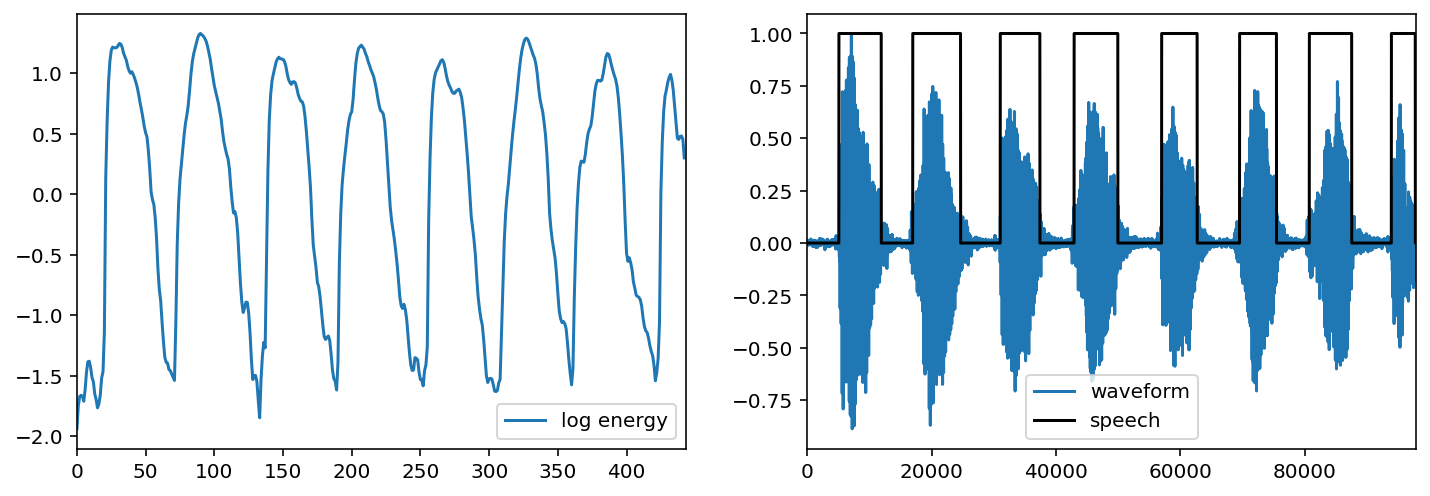

In [22]:
# waveforms of interest: 13 21 29 32 53 55
waveform = X[13][8000:-3000] #### crop range ####

win_len = int(sr * 0.025) # 25 ms
hop_len = int(sr * 0.010) # 10 ms

sframes = enframe(waveform, win_len, hop_len) # rows: frame index, cols: each frame

# percent_high_nrg is the VAD context ratio. It helps smooth the
# output VAD decisions. Higher values are more strict.
percent_high_nrg = 0.6
vad = nrg_vad(sframes, percent_high_nrg) #### nrg_thr ####

_, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(compute_log_nrg(sframes), label='log energy')
axes[0].set_xlim(0, len(sframes))
axes[0].legend()
axes[1].plot(waveform / waveform.max(), label='waveform')
axes[1].plot(deframe(vad, win_len, hop_len), c='k', label='speech')
axes[1].legend()
axes[1].set_xlim(0, len(waveform));

Остальные параметры VAD подбираем до тех пор, пока в каждом файле не будет обнаружено восемь слов, за исключением того, в котором их семь (`X[21]`).

In [23]:
#### Hyperparams: crop range, nrg_thr, context, frequencies, moving avg #### 
for i, x in enumerate(X):
    x = x[8000:-3000] #### crop range ####
    sframes = enframe(x, win_len, hop_len)
    vad = nrg_vad(sframes, 0.6) #### nrg_thr ####
    regions = deframe(vad, win_len, hop_len)
    words_num = ((regions[1:] - regions[:-1]) > 0).sum()
    if words_num != 8:
        print(f'{words_num} words in X[{i}]')

7 words in X[21]


Т.к. набор данных небольшой, мы можем посмотреть, как отрабатывает VAD для каждого примера.

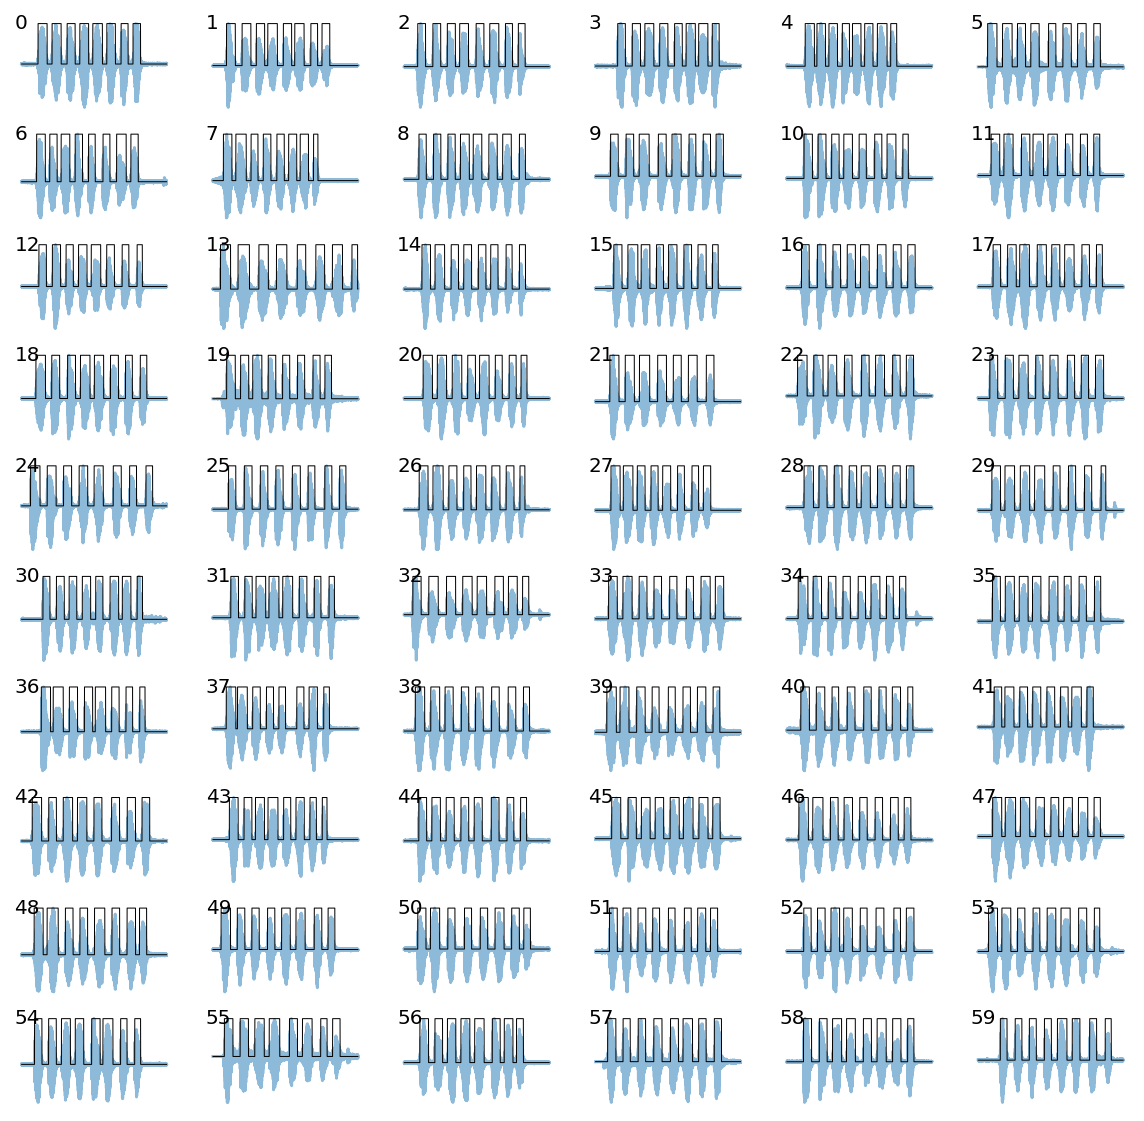

In [24]:
_, axes = plt.subplots(10, 6, figsize=(10, 10))
for i, ax_i in enumerate(axes):
    for j, ax_j in enumerate(ax_i):
        ind = i * len(ax_i) + j
        x = X[ind][8000:-3000]
        vad = nrg_vad(enframe(x, win_len, hop_len), 0.6)
        reg = deframe(vad, win_len, hop_len)
        ax_j.plot(x / x.max(), alpha=0.5)
        ax_j.plot(reg, c='k', lw=0.5)
        ax_j.set_axis_off()
        ax_j.annotate(text=ind, xy=(0., 0.9), xycoords='axes fraction')
plt.show()

Выглядит все довольно неплохо.

Теперь поменяем неправильную метку для 21-го примера в наборе данных.

In [25]:
print(f'old Y[21] label: {Y[21]}')
Y[21] = [0, 1, 0, 1, 0, 0, 0]
print(f'new Y[21] label: {Y[21]}')

old Y[21] label: [0, 1, 0, 1, 0, 0, 0, 0]
new Y[21] label: [0, 1, 0, 1, 0, 0, 0]


Разобьём набор данных на тренировочный и тестовый в соотношении 80% на 20%, обработаем полученные наборы данных с помощью VAD.

In [26]:
X_train, X_test, Y_train, Y_test = sklearn.model_selection.train_test_split(X, Y, test_size=0.2, random_state=1)

In [27]:
train_VA, test_VA = [], []

for i, x_tr in enumerate(X_train):
    X_train[i] = x_tr[8000:-3000]
    vad = nrg_vad(enframe(X_train[i], win_len, hop_len), 0.6)
    train_VA.append(deframe(vad, win_len, hop_len).flatten())

for i, x_t in enumerate(X_test):
    X_test[i] = x_t[8000:-3000]
    vad = nrg_vad(enframe(X_test[i], win_len, hop_len), 0.6)
    test_VA.append(deframe(vad, win_len, hop_len).flatten())

Итоговая проверка корректности работы VAD.

In [28]:
def test_VAD(VA, Y):
    def check_diff(diff, num_words):
        if diff.sum() != 0:
            print("VAD detected speech at the beginning (or end) of audio")
            return -1 
        if not (diff > 0).sum() == (diff > 0).sum() ==  num_words:
            print("Wrong number of words. Each audio contains 8 words") # except one
            return -2
        return 0
    
    for i, (va, y) in enumerate(zip(VA, Y)):
        diff = va[1:]  - va[:-1]
        assert check_diff(diff, len(y)) == 0, f"Bad {i} example"
    print("All ok!")

test_VAD(train_VA, Y_train)
test_VAD(test_VA, Y_test)

All ok!
All ok!


# Задание *5 (2 балла)
Обучите классификатор, определяющий, какое слово было сказано. Используйте VAD для разбиения входных файлов на отдельные слова. Классификацию можно сделать, например, с помощью SVM по усредненным признакам выделенных слов. Или любым другим удобным для вас способом.

Создадим тренировочный и тестовый наборы данных, состоящие непосредственно из слов "да" и "нет".

Вырежем из каждого файла слова. Для наглядности отобразим промежуточные этапы обработки.

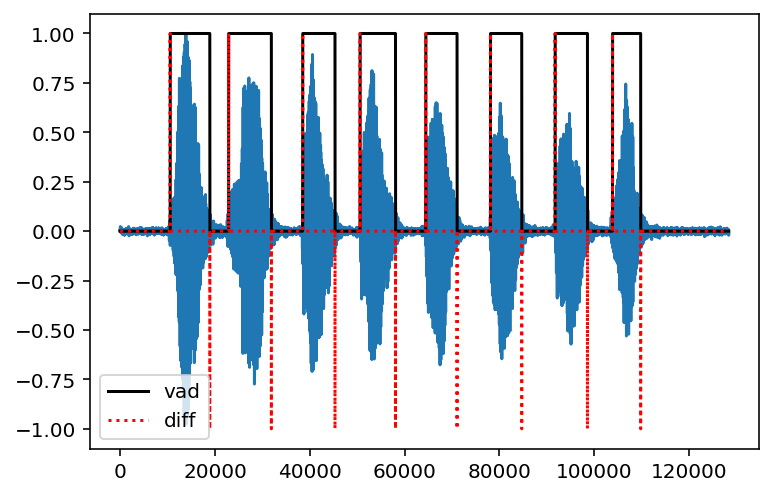

In [29]:
sample_num = 0 # train dataset sample number
plt.plot(X_train[sample_num] / X_train[sample_num].max())
plt.plot(train_VA[sample_num], c='k', label='vad')
plt.plot(np.diff(train_VA[sample_num]), c='r', ls='dotted', label='diff')
plt.legend(loc='lower left');

Так мы будем получать индексы, соответствующие началу и концу каждого слова.

In [30]:
np.nonzero(np.diff(train_VA[sample_num]))[0]

array([ 10559,  18919,  22879,  31899,  38499,  45319,  50599,  58079,
        64459,  71059,  78099,  84699,  91739,  98559, 103839, 109779])

Будем разбивать массив от его начала последовательно до каждого индекса, представленного выше. Чтобы выделить участки со словами из полученного списка подмассивов необходимо взять их все, начиная с первого индекса и далее через один.

In [31]:
len(np.split(X_train[sample_num], 
             np.nonzero(np.diff(train_VA[sample_num]))[0] + 1)[1::2])
# [1::2] -> we need every second value starting from index 1

8

Проверим работоспособность предложенного подхода.

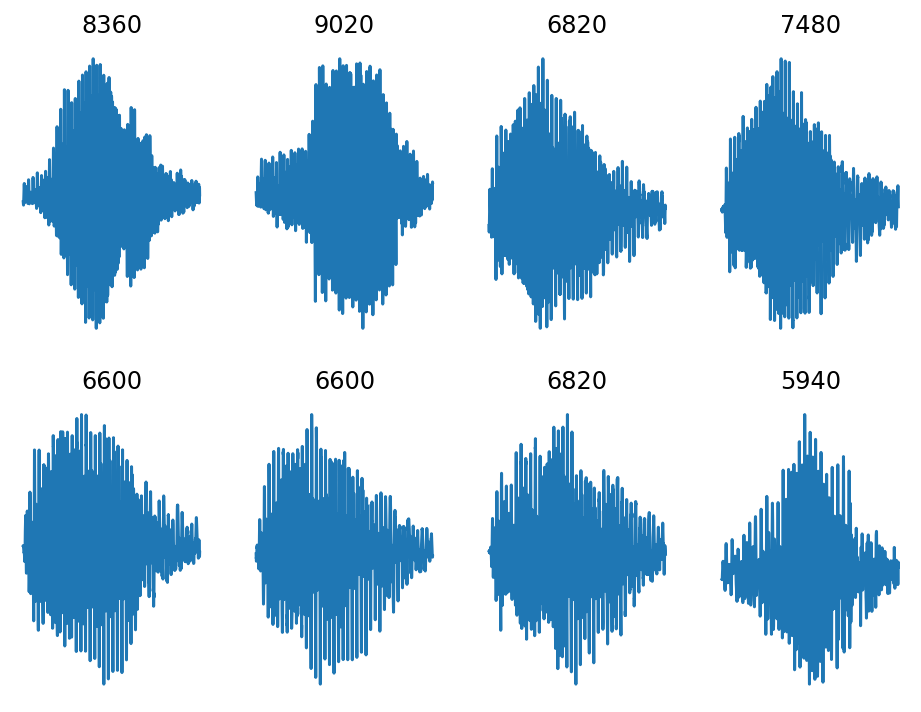

In [32]:
sample_words = np.split(X_train[sample_num], 
                        np.nonzero(np.diff(train_VA[sample_num]))[0] + 1)[1::2]
_, axes = plt.subplots(2, 4, figsize=(8, 6))
for i in range(2):
    for j in range(4):
        ind = i * 4 + j
        axes[i][j].set_title(sample_words[ind].shape[0])
        axes[i][j].plot(sample_words[ind])
        axes[i][j].set_axis_off()

Как можно убедиться на графике выше, слова из файла вырезаются правильно (сверху над каждым словом - число отсчётов).

Обработаем теперь таким образом весь набор данных.

In [33]:
X_words_train, X_words_test = [], []
Y_words_train, Y_words_test = [], []

for x_tr, y_tr, vad_tr in zip(X_train, Y_train, train_VA):
    # move identical elements in numpy array into subarrays
    # and get every second subarray starting from index 1
    words_from_file = np.split(x_tr, np.nonzero(np.diff(vad_tr))[0] + 1)[1::2]
    for word, label in zip(words_from_file, y_tr):
        X_words_train.append(word)
        Y_words_train.append(label)
    
for x_t, y_t, vad_t in zip(X_test, Y_test, test_VA):
    words_from_file = np.split(x_t, np.nonzero(np.diff(vad_t))[0] + 1)[1::2]
    for word, label in zip(words_from_file, y_t):
        X_words_test.append(word)
        Y_words_test.append(label)

In [34]:
print(f'class "1" ("yes") samples: {sum(Y_words_train + Y_words_test)}')
print(f'class "0" ("no")  samples: {len(Y_words_train + Y_words_test) - sum(Y_words_train + Y_words_test)}')

class "1" ("yes") samples: 251
class "0" ("no")  samples: 228


Посмотрим на гистограмму распределения длин слов в полученном наборе данных.

min length: 3851 samples
max length: 9900 samples


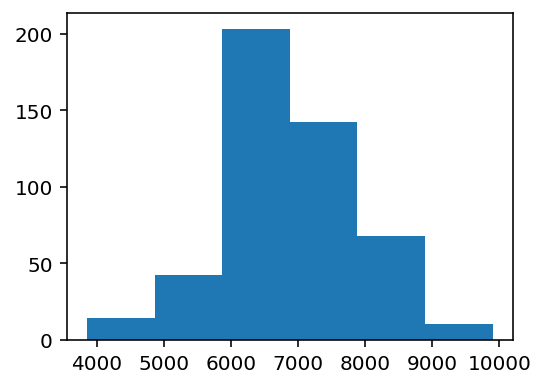

In [35]:
lengths_words = []
for w in X_words_train + X_words_test:
    lengths_words.append(w.shape[0])
print(f'min length: {min(lengths_words)} samples') 
print(f'max length: {max(lengths_words)} samples')
plt.figure(figsize=(4, 3))
plt.hist(lengths_words, bins=6);

Как видим, длины (длительности) различных слов сильно отличаются, но большинство из них лежит в диапазоне 6-7 тысяч отсчётов, что соответствует длительностям во времени от 272 до 317 мс. Выглядит вполне правдоподобно. 

В качестве признакового описания каждого из слов будем использовать мел-частотные кепстральные коэффициенты (MFCC). Посчитаем среднее этих коэффициентов  по времени, чтобы количество признаков, характеризующих каждое слово, было постоянным, и чтобы при этом они хорошо "описывали" каждое слово.

In [36]:
X_mfcc_train, X_mfcc_test = [], []

def get_mfcc_features(x):
    mfcc = get_mfcc(x, sr, n_mfcc=13)
    # mfcc = librosa.feature.mfcc(x, sr, n_fft=win_len, hop_length=hop_len, n_mfcc=13, n_mels=40, htk=True)
    return np.mean(mfcc, axis=1)

for x_tr in X_words_train:
    X_mfcc_train.append(get_mfcc_features(x_tr))

for x_t in X_words_test:
    X_mfcc_test.append(get_mfcc_features(x_t))

Визуализируем признаки для всех слов в наборе данных.

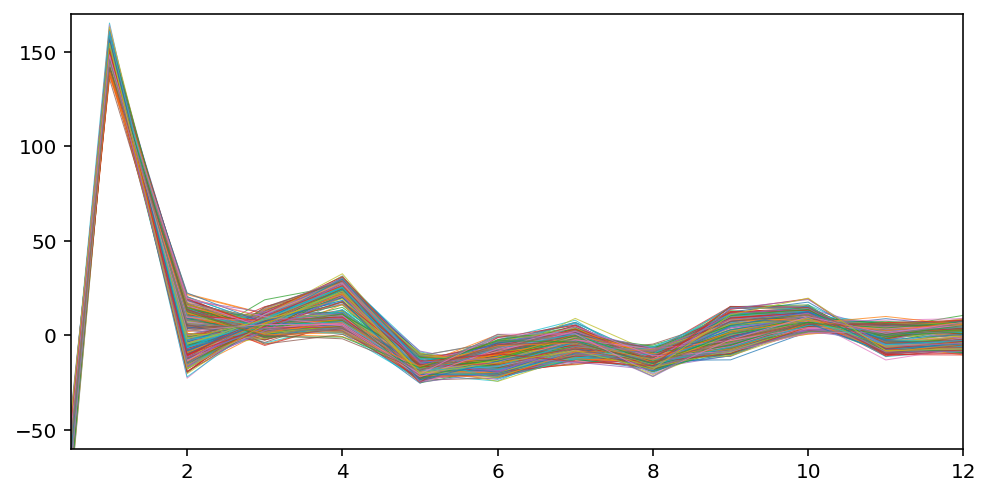

In [37]:
plt.figure(figsize=(8, 4))
for x in X_mfcc_train + X_mfcc_test:
    plt.plot(x, alpha=0.75, lw=0.5)
plt.ylim(-60, 170)
plt.xlim(0.5, X_mfcc_train[0].shape[0]-1);

Обучим несколько простых моделей, подобрав их параметры вручную.

**SVM**

In [38]:
clf = sklearn.svm.SVC(C=1.0, gamma='scale', probability=True)
clf.fit(X_mfcc_train, Y_words_train)

Y_pred_train = clf.predict(X_mfcc_train)
print(f'train acc: {sklearn.metrics.accuracy_score(Y_words_train, Y_pred_train):.3f}')
Y_pred_test = clf.predict(X_mfcc_test)
print(f' test acc: {sklearn.metrics.accuracy_score(Y_words_test, Y_pred_test):.3f}')

train acc: 1.000
 test acc: 1.000


In [39]:
print(sklearn.metrics.classification_report(Y_words_test, Y_pred_test))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        47
           1       1.00      1.00      1.00        49

    accuracy                           1.00        96
   macro avg       1.00      1.00      1.00        96
weighted avg       1.00      1.00      1.00        96



**Logistic Regression**

In [40]:
clf2 = sklearn.linear_model.LogisticRegression(penalty='l2', C=1.0, solver='liblinear')
clf2.fit(X_mfcc_train, Y_words_train)

Y_pred_train2 = clf2.predict(X_mfcc_train)
print(f'train acc: {sklearn.metrics.accuracy_score(Y_words_train, Y_pred_train2):.3f}')
Y_pred_test2 = clf2.predict(X_mfcc_test)
print(f' test acc: {sklearn.metrics.accuracy_score(Y_words_test, Y_pred_test2):.3f}')

train acc: 1.000
 test acc: 1.000


In [41]:
print(sklearn.metrics.classification_report(Y_words_test, Y_pred_test2))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        47
           1       1.00      1.00      1.00        49

    accuracy                           1.00        96
   macro avg       1.00      1.00      1.00        96
weighted avg       1.00      1.00      1.00        96



Вследствие того, что набор данных относительно невелик, решается задача бинарной классификации, а признаки спроектированы правильно, то простые модели даже с параметрами по умолчанию справляются с задачей на 100%.